# NB5 — Task 3: Transfer Learning with a pretrained ResNet-18
____________________________________________________________________________________________________

In NB1–NB4 every network started from **random weights** and learned everything from our 18,900 training images. Here we start from a network that has **already been trained on ImageNet** (1.28 million images, 1000 classes) and we reuse what it has learned.

a. The pretrained backbone: ResNet-18, input size and normalization

b. Three strategies (like the lab script `ClassificationTransferLearningFineTuning.py`):
   - (i) **frozen** feature extractor: only the new classification layer is trained
   - (ii) **partial fine-tuning**: the last residual block (`layer4`) is also trained
   - (iii) **full fine-tuning**: every layer is trained

c. Training helpers

d. **Data efficiency**: each strategy (and our best from-scratch CNN of NB4) is trained with 5 %, 10 %, 25 % and 100 % of the training set

e. Comparison: data efficiency, convergence speed, test metrics

f. Best model on the test set + checkpoint loading

## 0. Setup

In [1]:
import os
import json
import time
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

ON_KAGGLE = os.path.exists("/kaggle/input")

def find_path(name, search_roots):
    # walk the search folders and return the first file / folder called `name`
    for search_root in search_roots:
        for root, dirs, files in os.walk(search_root):
            if name in dirs or name in files:
                return os.path.join(root, name)
    return None

SEARCH_ROOTS = ["/kaggle/input"] if ON_KAGGLE else ["..", "../.."]
DATA_ROOT = find_path("EuroSAT_RGB", SEARCH_ROOTS)
SPLITS_FILE = find_path("splits.json", SEARCH_ROOTS)

OUT_DIR = "/kaggle/working" if ON_KAGGLE else "."
CKPT_DIR = os.path.join(OUT_DIR, "checkpoints")
RES_DIR = os.path.join(OUT_DIR, "results")
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

NUM_WORKERS = 4 if ON_KAGGLE else 0

print("DATA_ROOT  :", DATA_ROOT)
print("SPLITS_FILE:", SPLITS_FILE)

import torchvision.models as models
from sklearn.metrics import f1_score

Using device: cuda:0
DATA_ROOT  : /kaggle/input/datasets/waseemalastal/eurosat-rgb-dataset/EuroSAT_RGB
SPLITS_FILE: /kaggle/input/notebooks/emilioyared/aide500-nb0-setup-data-run-1010-1100/splits.json


## a. The pretrained backbone

**ResNet-18** (He et al., 2016): 4 stages of residual blocks (`layer1` … `layer4`) after a first 7×7 convolution, then a global average pooling and one fully connected layer `fc` (512 → 1000 ImageNet classes). 11.7 M parameters.

Two things must match what the network saw during its ImageNet training:

1. **Normalization.** The pretrained filters expect images normalized with the **ImageNet** mean and std, not the EuroSAT ones we used before:
   `mean = (0.485, 0.456, 0.406)`, `std = (0.229, 0.224, 0.225)`.

2. **Input size.** ResNet-18 divides the image size by 32 (a stride-2 convolution, a max pooling and 3 stride-2 stages). With our 64×64 images the last feature maps would be only **2×2**, and the pretrained filters would see objects much smaller than in ImageNet (224×224). We therefore **upsample the images to 128×128** (`transforms.Resize(128)`): last feature maps 4×4. (224×224 would be ~3× slower for a small gain.)

The from-scratch CNN keeps its own 64×64 images and EuroSAT normalization, exactly as in NB4.

**Augmentation:** for a fair comparison, every model uses the best augmentation of NB4 without mixing: **flips + 90° rotations + random crop**. It is applied on the 64×64 image, **before** the resize.

In [2]:
with open(SPLITS_FILE) as f:
    splits = json.load(f)

classes = splits["classes"]
num_classes = len(classes)
MEAN, STD = splits["mean"], splits["std"]                          # EuroSAT statistics (from-scratch CNN)
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet statistics (ResNet-18)
RESNET_SIZE = 128

augmentation = [transforms.RandomHorizontalFlip(p=0.5),
                transforms.RandomVerticalFlip(p=0.5),
                transforms.RandomChoice([transforms.RandomRotation((a, a)) for a in (0, 90, 180, 270)]),
                transforms.RandomCrop(64, padding=4, padding_mode="reflect")]

# "resnet": resize to 128 + ImageNet normalization | "scratch": 64x64 + EuroSAT normalization
TRANSFORMS = {
    "resnet": {"train": transforms.Compose(augmentation + [transforms.Resize(RESNET_SIZE), transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
               "eval": transforms.Compose([transforms.Resize(RESNET_SIZE), transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])},
    "scratch": {"train": transforms.Compose(augmentation + [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]),
                "eval": transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])},
}

BATCH_SIZE = 64
val_loaders, test_loaders, train_datasets = {}, {}, {}
for kind in TRANSFORMS:
    train_datasets[kind] = torchvision.datasets.ImageFolder(root=DATA_ROOT, transform=TRANSFORMS[kind]["train"])
    eval_dataset = torchvision.datasets.ImageFolder(root=DATA_ROOT, transform=TRANSFORMS[kind]["eval"])
    val_loaders[kind] = DataLoader(Subset(eval_dataset, splits["val"]), batch_size=256, shuffle=False, num_workers=NUM_WORKERS)
    test_loaders[kind] = DataLoader(Subset(eval_dataset, splits["test"]), batch_size=256, shuffle=False, num_workers=NUM_WORKERS)
print("train: %d | val: %d | test: %d" % (len(splits["train"]), len(splits["val"]), len(splits["test"])))

train: 18900 | val: 4050 | test: 4050


**Training subsets for the data-efficiency study.** We take 5 %, 10 %, 25 % and 100 % of the training set, **stratified** (the same fraction of every class), and **nested**: the 5 % subset is included in the 10 % subset, itself included in the 25 % one. So a bigger fraction only *adds* images, and the comparison between fractions is not influenced by "lucky" or "unlucky" image choices.

Validation and test sets are always complete.

In [3]:
FRACTIONS = [0.05, 0.10, 0.25, 1.0]

# for each class: the training indices of that class in a fixed random order
rng = np.random.RandomState(0)
train_targets = np.array(train_datasets["scratch"].targets)[splits["train"]]
class_orders = []
for c in range(num_classes):
    idx = np.array(splits["train"])[train_targets == c]
    class_orders.append(rng.permutation(idx))

def train_subset(frac):
    # first frac of each class -> stratified and nested subsets
    idx = []
    for order in class_orders:
        idx += order[:int(round(frac * len(order)))].tolist()
    return sorted(idx)

for frac in FRACTIONS:
    print("%5.0f %% of the training set: %5d images" % (100 * frac, len(train_subset(frac))))

    5 % of the training set:   947 images
   10 % of the training set:  1890 images
   25 % of the training set:  4727 images
  100 % of the training set: 18900 images


**Number of epochs.** With 5 % of the data, one epoch is only 15 mini-batches: 15 epochs would be far too few updates to train anything. We give more epochs to the smaller subsets (the same for every model at a given fraction):

| fraction | 5 % | 10 % | 25 % | 100 % |
|---|---|---|---|---|
| epochs | 60 | 50 | 30 | 15 |
| mini-batches (updates) | ~900 | ~1,500 | ~2,200 | ~4,450 |

All runs use Adam with a **cosine** learning-rate schedule over their own number of epochs (it adapts automatically to any length, unlike StepLR whose steps every 10 epochs were tuned for 25 epochs in NB3).

In [4]:
EPOCHS = {0.05: 60, 0.10: 50, 0.25: 30, 1.0: 15}
for frac in FRACTIONS:
    print("%5.0f %%: %d epochs x %d mini-batches = %d updates" % (100 * frac, EPOCHS[frac], np.ceil(len(train_subset(frac)) / BATCH_SIZE),
          EPOCHS[frac] * np.ceil(len(train_subset(frac)) / BATCH_SIZE)))

    5 %: 60 epochs x 15 mini-batches = 900 updates
   10 %: 50 epochs x 30 mini-batches = 1500 updates
   25 %: 30 epochs x 74 mini-batches = 2220 updates
  100 %: 15 epochs x 296 mini-batches = 4440 updates


## b. The three transfer-learning strategies

As in the lab script, we load ResNet-18 with its ImageNet weights, **freeze** parameters with `param.requires_grad = False` (no gradient is computed for them, so `optimizer.step()` never changes them), and **replace the last layer** `fc` by a new one with 10 outputs:

```python
model.fc = nn.Sequential(nn.Dropout(0.5), nn.Linear(model.fc.in_features, 10))
```

The new `fc` is created **after** the freezing loop, so its parameters are trainable (`requires_grad=True` by default).

| Strategy | Trained layers | Learning rate |
|---|---|---|
| (i) frozen | new `fc` only | 1e-3 |
| (ii) partial | `layer4` + new `fc` | 1e-4 for `layer4`, 1e-3 for `fc` |
| (iii) full | everything | 1e-4 for the backbone, 1e-3 for `fc` |

**Why a smaller learning rate for the pretrained layers?** The new `fc` starts from random weights and must learn fast. The pretrained layers are already good: big steps would destroy what they learned on ImageNet ("catastrophic forgetting"), especially at the beginning when the gradients coming from the random `fc` are noisy. Adam accepts **parameter groups**, each with its own learning rate.

**Why would partial fine-tuning make sense?** The first layers of a CNN learn generic features (edges, colors, textures), useful for any image. The last layers learn features specific to ImageNet objects (dog faces, wheels...). For satellite images, the last layers are the ones that need to change most.

**From scratch** (for comparison): the best `ConfigNet` of NB2–NB4, all its parameters trained with lr 1e-3.

In [5]:
WEIGHTS = models.ResNet18_Weights.IMAGENET1K_V1   # downloaded from the internet the first time, then cached
# (offline, as in the lab: models.resnet18(weights=None) + model.load_state_dict(torch.load("resnet18-f37072fd.pth")))


def make_resnet(strategy):
    model = models.resnet18(weights=WEIGHTS)
    for param in model.parameters():
        param.requires_grad = False                 # freeze everything
    if strategy == "partial":
        for param in model.layer4.parameters():
            param.requires_grad = True              # unfreeze the last residual block
    if strategy == "full":
        for param in model.parameters():
            param.requires_grad = True              # unfreeze everything
    # new classification layer (trainable by default)
    model.fc = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(model.fc.in_features, num_classes))
    return model

In [6]:
class ConfigNet(nn.Module):
    def __init__(self, n_blocks=3, kernel_size=3, padding="same", downsample="pool", use_bn=False, n_fc=2, num_classes=10):
        super(ConfigNet, self).__init__()
        channels = [3] + [min(32 * 2 ** i, 256) for i in range(n_blocks)]  # e.g. n_blocks=3 -> [3, 32, 64, 128]
        p = kernel_size // 2 if padding == "same" else 0
        s = 2 if downsample == "stride" else 1

        blocks = []
        h = 64  # input images are 64x64
        for i in range(n_blocks):
            layers = []
            # with BatchNorm, the conv bias is useless (BN subtracts the mean and adds its own bias beta)
            layers.append(nn.Conv2d(channels[i], channels[i + 1], kernel_size, stride=s, padding=p, bias=not use_bn))
            h = (h + 2 * p - kernel_size) // s + 1           # size after the convolution
            if use_bn:
                layers.append(nn.BatchNorm2d(channels[i + 1]))
            layers.append(nn.ReLU())
            if downsample == "pool":
                layers.append(nn.MaxPool2d(2, 2))
                h = (h - 2) // 2 + 1                         # size after the pooling
            blocks.append(nn.Sequential(*layers))
        self.features = nn.Sequential(*blocks)

        assert h >= 1, "the feature maps disappear (size %d): too many blocks for this padding / kernel" % h
        self.flat_features = channels[-1] * h * h            # number of inputs of the first fc layer
        self.out_size = h

        # fully connected layers: 1 -> [flat, 10] | 2 -> [flat, 256, 10] | 3 -> [flat, 256, 128, 10]
        fc_sizes = [self.flat_features] + [256, 128][:n_fc - 1] + [num_classes]
        fc_layers = []
        for i in range(n_fc):
            fc_layers.append(nn.Linear(fc_sizes[i], fc_sizes[i + 1]))
            if i < n_fc - 1:                                 # no ReLU after the last layer (we want raw scores)
                fc_layers.append(nn.ReLU())
        self.classifier = nn.Sequential(*fc_layers)

    def forward(self, x):
        x = self.features(x)                     # [B, C, h, h]
        x = x.view(-1, self.flat_features)       # [B, C*h*h] flatten
        x = self.classifier(x)                   # [B, 10]
        return x


# check: the default configuration is exactly the baseline of NB1
net = ConfigNet()
print(net)
print("last feature maps: %dx%d | flat features: %d" % (net.out_size, net.out_size, net.flat_features))
print("parameters:", sum(p.numel() for p in net.parameters()))

ConfigNet(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): Linear(in_features=8192, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=10, bias=True)
  )
)
last feature maps: 8x8 | flat features: 8192
parameters: 2193226


In [7]:
BEST4_FILE = find_path("NB4_best_recipe.json", SEARCH_ROOTS)
if BEST4_FILE is not None:
    with open(BEST4_FILE) as f:
        best4 = json.load(f)
    ARCH = best4["arch"]
    print("from-scratch architecture from NB4 (%s): %s (NB4 test acc %.2f %%)" % (BEST4_FILE, ARCH, best4["test_acc"]))
else:
    ARCH = dict(n_blocks=5, kernel_size=3, padding="same", downsample="pool", use_bn=True, n_fc=2)
    print("NB4_best_recipe.json not found -> default architecture:", ARCH)

METHODS = ["scratch", "frozen", "partial", "full"]


def make_model(method):
    # returns the network and the parameter groups given to the optimizer
    if method == "scratch":
        net = ConfigNet(**ARCH)
        return net, [{"params": net.parameters(), "lr": 1e-3}]
    net = make_resnet(method)
    head = list(net.fc.parameters())
    backbone = [p for name, p in net.named_parameters() if p.requires_grad and not name.startswith("fc.")]
    groups = [{"params": head, "lr": 1e-3}]
    if len(backbone) > 0:
        groups.append({"params": backbone, "lr": 1e-4})
    return net, groups


print('%-8s %12s %18s' % ('method', 'parameters', 'trainable params'))
for method in METHODS:
    net, _ = make_model(method)
    print('%-8s %12d %18d' % (method, sum(p.numel() for p in net.parameters()),
                              sum(p.numel() for p in net.parameters() if p.requires_grad)))

from-scratch architecture from NB4 (/kaggle/input/notebooks/emilioyared/aide500-nb4-data-augmentation-run-1010-1518/results/NB4_best_recipe.json): {'n_blocks': 5, 'n_fc': 2, 'kernel_size': 3, 'padding': 'same', 'downsample': 'pool', 'use_bn': True} (NB4 test acc 97.04 %)
method     parameters   trainable params
scratch       1244202            1244202
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 178MB/s]


frozen       11181642               5130
partial      11181642            8398858
full         11181642           11181642


Frozen: only 5,130 parameters are trained (512 × 10 weights + 10 biases): it is just a **linear classifier on top of fixed ImageNet features**.

**A detail about BatchNorm in the frozen layers.** `requires_grad = False` freezes the weights $\gamma, \beta$ of the BatchNorm layers, but in `net.train()` mode BatchNorm still **updates its running mean and variance** with the EuroSAT batches (these statistics are not parameters, they are buffers, and they are not updated by the optimizer). So the "frozen" backbone still adapts its normalization to the new images. This is what the lab script does too, and it usually helps when the new images look very different from ImageNet.

## c. Training helpers

The same loops as before. `evaluate` also returns the macro **F1-score** (the average over the classes of the harmonic mean of precision and recall), a usual test metric besides accuracy.

In [8]:
def train_one_epoch(net, loader, criterion, optimizer):
    net.train()
    running_loss, correct, total = 0.0, 0, 0
    for i, data in enumerate(loader, 0):
        inputs, labels = data[0].to(device), data[1].to(device)

        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, 100.0 * correct / total


def evaluate(net, loader, criterion):
    net.eval()
    running_loss, total = 0.0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for data in loader:
            images, labels = data[0].to(device), data[1].to(device)
            outputs = net(images)
            running_loss += criterion(outputs, labels).item() * labels.size(0)
            _, predicted = torch.max(outputs, 1)
            all_preds.append(predicted.cpu())
            all_labels.append(labels.cpu())
            total += labels.size(0)
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    acc = 100.0 * (all_preds == all_labels).mean()
    per_class_acc = [100.0 * (all_preds[all_labels == c] == c).mean() for c in range(num_classes)]
    return running_loss / total, acc, per_class_acc, all_preds, all_labels


def measure_latency(net, size, n_runs=100):
    net.eval()
    x = torch.randn(1, 3, size, size).to(device)
    with torch.no_grad():
        for _ in range(10):  # warm-up
            net(x)
        if device.type == "cuda": torch.cuda.synchronize()
        start = time.time()
        for _ in range(n_runs):
            net(x)
        if device.type == "cuda": torch.cuda.synchronize()
    return (time.time() - start) / n_runs * 1000  # milliseconds per image

In [9]:
criterion = nn.CrossEntropyLoss()
all_histories = {}
all_summaries = {}


def run_experiment(method, frac):
    name = "%s_%dpct" % (method, round(100 * frac))
    set_seed(SEED)
    n_epochs = EPOCHS[frac]
    kind = "scratch" if method == "scratch" else "resnet"
    trainloader = DataLoader(Subset(train_datasets[kind], train_subset(frac)), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
    net, param_groups = make_model(method)
    net = net.to(device)
    optimizer = optim.Adam(param_groups)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)
    ckpt_path = os.path.join(CKPT_DIR, "NB5_%s.pth" % name)
    print('===== %s | %d training images | %d epochs =====' % (name, len(trainloader.dataset), n_epochs))

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_per_class_acc": [], "epoch_time": []}
    best_val_acc = 0.0
    for epoch in range(n_epochs):
        start = time.time()
        train_loss, train_acc = train_one_epoch(net, trainloader, criterion, optimizer)
        val_loss, val_acc, val_per_class_acc, _, _ = evaluate(net, val_loaders[kind], criterion)
        scheduler.step()
        epoch_time = time.time() - start

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_per_class_acc"].append(val_per_class_acc)
        history["epoch_time"].append(epoch_time)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(net.state_dict(), ckpt_path)

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print('[epoch %2d] train loss: %.3f | train acc: %.2f %% | val loss: %.3f | val acc: %.2f %% | %.1f s' %
                  (epoch + 1, train_loss, train_acc, val_loss, val_acc, epoch_time))

    # test metrics of the best checkpoint (chosen on the validation set)
    net.load_state_dict(torch.load(ckpt_path, map_location=device))
    _, test_acc, test_per_class_acc, test_preds, test_labels = evaluate(net, test_loaders[kind], criterion)

    best_epoch = int(np.argmax(history["val_acc"]))
    reached = [e + 1 for e, a in enumerate(history["val_acc"]) if a >= 90.0]
    summary = {
        "name": name, "method": method, "fraction": frac, "n_train": len(trainloader.dataset), "n_epochs": n_epochs,
        "best_val_acc": best_val_acc, "best_epoch": best_epoch + 1,
        "gen_gap": history["train_acc"][best_epoch] - history["val_acc"][best_epoch],
        "epochs_to_90": reached[0] if reached else None,
        "time_to_90_s": sum(history["epoch_time"][:reached[0]]) if reached else None,
        "test_acc": test_acc,
        "test_f1_macro": 100.0 * f1_score(test_labels, test_preds, average="macro"),
        "test_per_class_acc": test_per_class_acc,
        "train_time_s": sum(history["epoch_time"]),
    }
    print('-> best val acc: %.2f %% (epoch %d) | test acc: %.2f %% | test macro-F1: %.2f | epochs to 90%%: %s | %.0f s' %
          (best_val_acc, best_epoch + 1, test_acc, summary["test_f1_macro"], summary["epochs_to_90"], summary["train_time_s"]))

    all_histories[name] = history
    all_summaries[name] = summary
    with open(os.path.join(RES_DIR, "NB5_%s_history.json" % name), "w") as f:
        json.dump(history, f)
    return summary

## d. Experiments: 4 methods × 4 data fractions = 16 trainings

The test accuracy of each run is computed once, on its best checkpoint (chosen with the validation set), so that we can draw the data-efficiency curves on the test set.

In [10]:
for frac in FRACTIONS:
    run_experiment("scratch", frac)

===== scratch_5pct | 947 training images | 60 epochs =====
[epoch  1] train loss: 1.680 | train acc: 36.64 % | val loss: 2.253 | val acc: 28.99 % | 6.6 s
[epoch  5] train loss: 0.778 | train acc: 72.12 % | val loss: 1.138 | val acc: 62.07 % | 2.6 s
[epoch 10] train loss: 0.665 | train acc: 75.92 % | val loss: 0.751 | val acc: 72.35 % | 2.5 s
[epoch 15] train loss: 0.522 | train acc: 81.63 % | val loss: 0.609 | val acc: 78.91 % | 2.5 s
[epoch 20] train loss: 0.477 | train acc: 82.26 % | val loss: 0.898 | val acc: 70.99 % | 2.5 s
[epoch 25] train loss: 0.340 | train acc: 87.22 % | val loss: 0.569 | val acc: 80.10 % | 2.6 s
[epoch 30] train loss: 0.345 | train acc: 87.65 % | val loss: 0.500 | val acc: 82.22 % | 2.7 s
[epoch 35] train loss: 0.236 | train acc: 92.93 % | val loss: 0.520 | val acc: 82.32 % | 2.6 s
[epoch 40] train loss: 0.172 | train acc: 93.77 % | val loss: 0.506 | val acc: 83.53 % | 2.6 s
[epoch 45] train loss: 0.130 | train acc: 95.56 % | val loss: 0.440 | val acc: 85.83 %

In [11]:
for frac in FRACTIONS:
    run_experiment("frozen", frac)

===== frozen_5pct | 947 training images | 60 epochs =====
[epoch  1] train loss: 2.374 | train acc: 17.21 % | val loss: 1.838 | val acc: 37.33 % | 4.5 s
[epoch  5] train loss: 1.077 | train acc: 66.53 % | val loss: 0.831 | val acc: 79.70 % | 4.4 s
[epoch 10] train loss: 0.700 | train acc: 78.04 % | val loss: 0.601 | val acc: 84.20 % | 4.3 s
[epoch 15] train loss: 0.646 | train acc: 79.20 % | val loss: 0.532 | val acc: 84.86 % | 4.2 s
[epoch 20] train loss: 0.588 | train acc: 81.10 % | val loss: 0.495 | val acc: 85.73 % | 4.0 s
[epoch 25] train loss: 0.561 | train acc: 81.31 % | val loss: 0.467 | val acc: 86.32 % | 3.9 s
[epoch 30] train loss: 0.537 | train acc: 82.26 % | val loss: 0.453 | val acc: 86.37 % | 3.9 s
[epoch 35] train loss: 0.497 | train acc: 83.53 % | val loss: 0.445 | val acc: 86.52 % | 3.9 s
[epoch 40] train loss: 0.560 | train acc: 79.30 % | val loss: 0.438 | val acc: 86.72 % | 3.9 s
[epoch 45] train loss: 0.485 | train acc: 83.32 % | val loss: 0.433 | val acc: 86.81 % 

In [12]:
for frac in FRACTIONS:
    run_experiment("partial", frac)

===== partial_5pct | 947 training images | 60 epochs =====
[epoch  1] train loss: 1.665 | train acc: 45.51 % | val loss: 0.979 | val acc: 77.11 % | 4.2 s
[epoch  5] train loss: 0.227 | train acc: 92.93 % | val loss: 0.245 | val acc: 91.83 % | 4.2 s
[epoch 10] train loss: 0.102 | train acc: 97.36 % | val loss: 0.217 | val acc: 92.77 % | 4.1 s
[epoch 15] train loss: 0.064 | train acc: 97.78 % | val loss: 0.192 | val acc: 93.80 % | 4.1 s
[epoch 20] train loss: 0.042 | train acc: 98.42 % | val loss: 0.185 | val acc: 93.93 % | 4.2 s
[epoch 25] train loss: 0.050 | train acc: 98.10 % | val loss: 0.181 | val acc: 94.15 % | 4.2 s
[epoch 30] train loss: 0.030 | train acc: 98.94 % | val loss: 0.194 | val acc: 94.02 % | 4.2 s
[epoch 35] train loss: 0.021 | train acc: 99.37 % | val loss: 0.189 | val acc: 94.35 % | 4.3 s
[epoch 40] train loss: 0.019 | train acc: 99.47 % | val loss: 0.180 | val acc: 94.35 % | 4.3 s
[epoch 45] train loss: 0.017 | train acc: 99.47 % | val loss: 0.180 | val acc: 94.37 %

In [13]:
for frac in FRACTIONS:
    run_experiment("full", frac)

===== full_5pct | 947 training images | 60 epochs =====
[epoch  1] train loss: 1.549 | train acc: 48.26 % | val loss: 0.811 | val acc: 79.80 % | 4.9 s
[epoch  5] train loss: 0.155 | train acc: 95.35 % | val loss: 0.180 | val acc: 94.12 % | 4.7 s
[epoch 10] train loss: 0.056 | train acc: 98.20 % | val loss: 0.183 | val acc: 94.20 % | 4.6 s
[epoch 15] train loss: 0.044 | train acc: 98.94 % | val loss: 0.157 | val acc: 95.51 % | 4.5 s
[epoch 20] train loss: 0.023 | train acc: 99.47 % | val loss: 0.164 | val acc: 95.19 % | 4.9 s
[epoch 25] train loss: 0.037 | train acc: 99.05 % | val loss: 0.158 | val acc: 95.38 % | 4.6 s
[epoch 30] train loss: 0.016 | train acc: 99.68 % | val loss: 0.158 | val acc: 95.28 % | 4.8 s
[epoch 35] train loss: 0.019 | train acc: 99.68 % | val loss: 0.161 | val acc: 95.70 % | 4.6 s
[epoch 40] train loss: 0.015 | train acc: 99.68 % | val loss: 0.154 | val acc: 95.85 % | 4.6 s
[epoch 45] train loss: 0.009 | train acc: 99.68 % | val loss: 0.155 | val acc: 95.95 % | 

## e. Comparison

In [14]:
print('%-17s %8s %7s %13s %10s %10s %8s %12s %12s %10s' % ('run', 'n_train', 'epochs', 'best val acc', 'test acc', 'macro-F1', 'gap', 'epochs->90%', 'time->90%', 'time (s)'))
print('-' * 125)
for name, s in all_summaries.items():
    print('%-17s %8d %7d %12.2f%% %9.2f%% %10.2f %8.2f %12s %12s %10.0f' % (name, s["n_train"], s["n_epochs"], s["best_val_acc"], s["test_acc"],
          s["test_f1_macro"], s["gen_gap"], s["epochs_to_90"] if s["epochs_to_90"] else "never",
          "%.0f s" % s["time_to_90_s"] if s["time_to_90_s"] else "never", s["train_time_s"]))

with open(os.path.join(RES_DIR, "NB5_summaries.json"), "w") as f:
    json.dump({"arch": ARCH, "epochs": {str(k): v for k, v in EPOCHS.items()}, "summaries": all_summaries}, f, indent=2)

run                n_train  epochs  best val acc   test acc   macro-F1      gap  epochs->90%    time->90%   time (s)
-----------------------------------------------------------------------------------------------------------------------------
scratch_5pct           947      60        87.73%     87.85%      87.44     8.79        never        never        160
scratch_10pct         1890      50        92.02%     91.88%      91.60     4.91           35        113 s        161
scratch_25pct         4727      30        94.27%     94.91%      94.76     1.86           18         89 s        148
scratch_100pct       18900      15        96.22%     96.64%      96.55     0.00            6         92 s        221
frozen_5pct            947      60        87.11%     87.51%      86.95    -5.06        never        never        244
frozen_10pct          1890      50        88.27%     88.59%      88.08    -4.73        never        never        241
frozen_25pct          4727      30        88.91%     89

**Data efficiency:** test accuracy as a function of the amount of training data (log scale). The vertical distance between two curves is what the pretrained ImageNet features are worth at that amount of data.

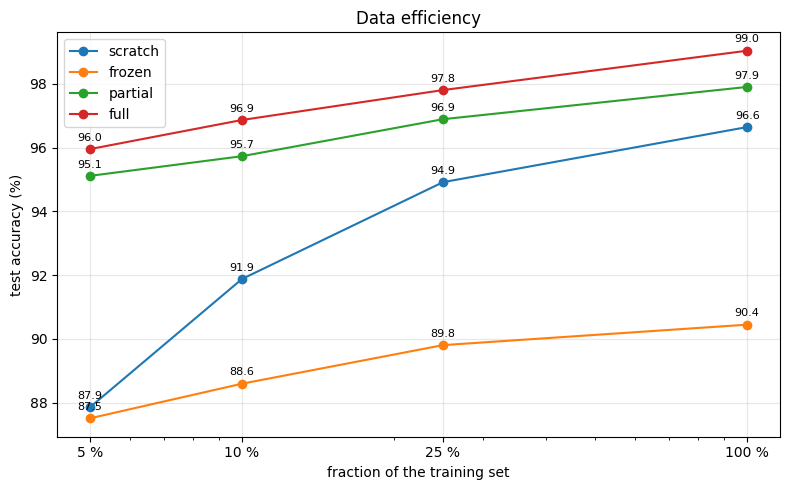

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
for method in METHODS:
    accs = [all_summaries["%s_%dpct" % (method, round(100 * frac))]["test_acc"] for frac in FRACTIONS]
    ax.plot([100 * frac for frac in FRACTIONS], accs, "o-", label=method)
    for frac, a in zip(FRACTIONS, accs):
        ax.annotate("%.1f" % a, (100 * frac, a), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
ax.set_xscale("log"); ax.set_xticks([100 * frac for frac in FRACTIONS]); ax.set_xticklabels(["5 %", "10 %", "25 %", "100 %"])
ax.set_xlabel("fraction of the training set"); ax.set_ylabel("test accuracy (%)"); ax.set_title("Data efficiency")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Convergence speed:** validation accuracy per epoch, with 100 % of the data (left) and with 5 % (right).

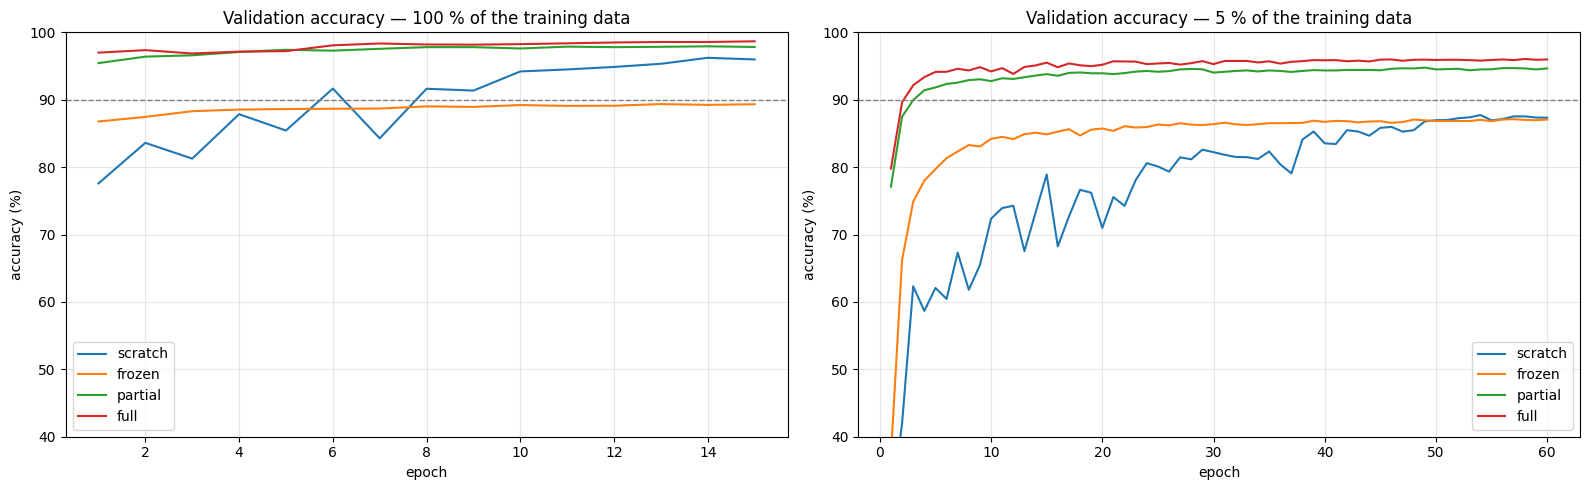

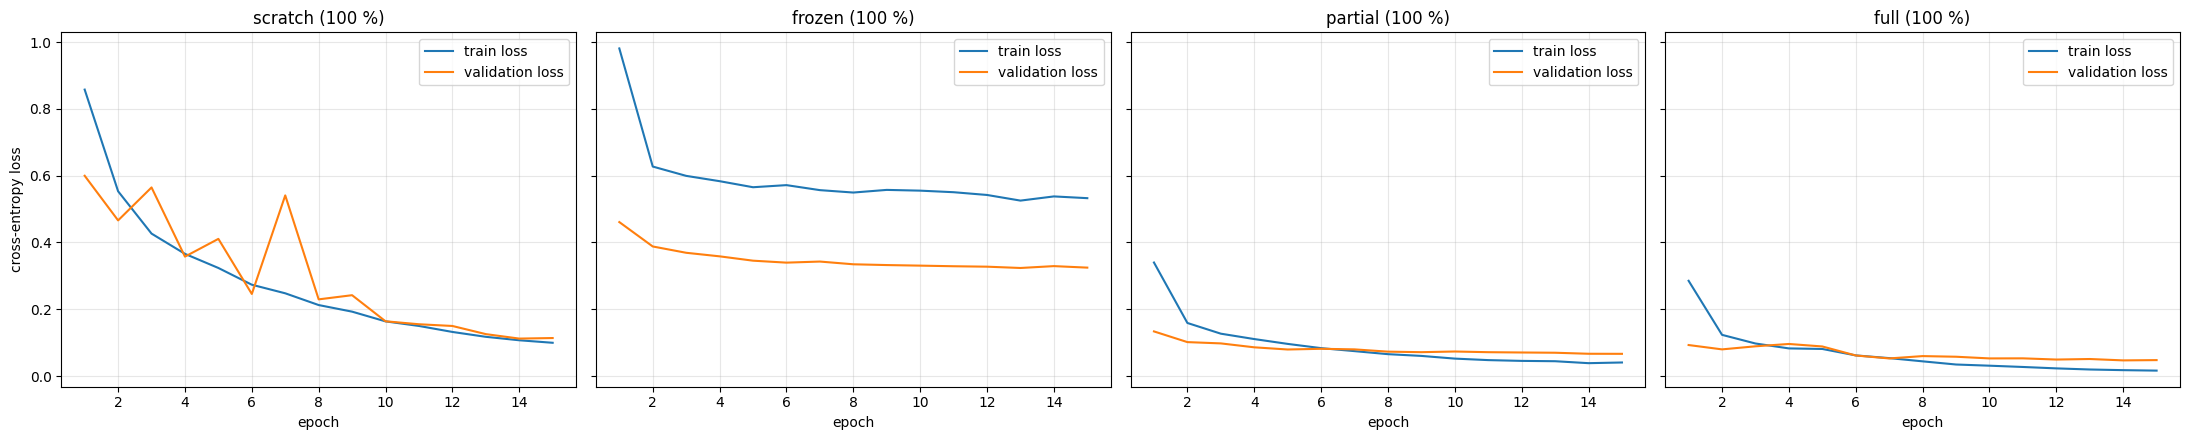

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, frac in zip(axes, [1.0, 0.05]):
    for method in METHODS:
        h = all_histories["%s_%dpct" % (method, round(100 * frac))]
        ax.plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], label=method)
    ax.axhline(90, color="grey", ls="--", lw=1)
    ax.set_title("Validation accuracy — %d %% of the training data" % round(100 * frac))
    ax.set_xlabel("epoch"); ax.set_ylabel("accuracy (%)"); ax.set_ylim(40, 100); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(22, 4.5), sharey=True)
for ax, method in zip(axes, METHODS):
    h = all_histories["%s_100pct" % method]
    ep = range(1, len(h["val_acc"]) + 1)
    ax.plot(ep, h["train_loss"], label="train loss"); ax.plot(ep, h["val_loss"], label="validation loss")
    ax.set_title("%s (100 %%)" % method); ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylabel("cross-entropy loss")
plt.tight_layout()
plt.show()

**Cost of each model:** a better accuracy is not free. ResNet-18 has ~10× more parameters than our CNN, and works on 4× more pixels (128×128 instead of 64×64).

In [17]:
cost = {}
for method in ["scratch", "frozen"]:     # frozen / partial / full: same network at inference
    net, _ = make_model(method)
    net = net.to(device)
    size = 64 if method == "scratch" else RESNET_SIZE
    cost[method] = (sum(p.numel() for p in net.parameters()), measure_latency(net, size))
cost["partial"] = cost["full"] = cost["frozen"]

print('%-8s %12s %18s %13s %14s %14s %16s' % ('method', 'params', 'trainable params', 'latency (ms)', 'test acc 100%', 'test acc 5%', 'train time 100%'))
print('-' * 105)
for method in METHODS:
    net, _ = make_model(method)
    s100, s5 = all_summaries["%s_100pct" % method], all_summaries["%s_5pct" % method]
    print('%-8s %12d %18d %13.3f %13.2f%% %13.2f%% %15.0f s' % (method, cost[method][0], sum(p.numel() for p in net.parameters() if p.requires_grad),
          cost[method][1], s100["test_acc"], s5["test_acc"], s100["train_time_s"]))
    for name in all_summaries:
        if all_summaries[name]["method"] == method:
            all_summaries[name]["params"], all_summaries[name]["latency_ms"] = cost[method]

with open(os.path.join(RES_DIR, "NB5_summaries.json"), "w") as f:
    json.dump({"arch": ARCH, "epochs": {str(k): v for k, v in EPOCHS.items()}, "summaries": all_summaries}, f, indent=2)

method         params   trainable params  latency (ms)  test acc 100%    test acc 5%  train time 100%
---------------------------------------------------------------------------------------------------------
scratch       1244202            1244202         0.745         96.64%         87.85%             221 s
frozen       11181642               5130         2.516         90.44%         87.51%             285 s
partial      11181642            8398858         2.516         97.90%         95.11%             307 s
full         11181642           11181642         2.516         99.04%         95.95%             372 s


## f. Best model on the test set

The best run is chosen on the **validation** accuracy, among the runs with 100 % of the data.

In [18]:
best_name = max([n for n in all_summaries if all_summaries[n]["fraction"] == 1.0], key=lambda n: all_summaries[n]["best_val_acc"])
best = all_summaries[best_name]
print("best run:", best_name)
print('Accuracy of the network on the %d test images: %.2f %% | macro-F1: %.2f' % (len(splits["test"]), best["test_acc"], best["test_f1_macro"]))
for c in range(num_classes):
    print('Accuracy of %22s : %.1f %%' % (classes[c], best["test_per_class_acc"][c]))

best_net, _ = make_model(best["method"])
best_net = best_net.to(device)
best_net.load_state_dict(torch.load(os.path.join(CKPT_DIR, "NB5_%s.pth" % best_name), map_location=device))
kind = "scratch" if best["method"] == "scratch" else "resnet"
_, _, _, test_preds, test_labels = evaluate(best_net, test_loaders[kind], criterion)

with open(os.path.join(RES_DIR, "NB5_best.json"), "w") as f:
    json.dump({"name": best_name, "method": best["method"], "test_acc": best["test_acc"], "test_f1_macro": best["test_f1_macro"],
               "params": best["params"], "latency_ms": best["latency_ms"]}, f, indent=2)

best run: full_100pct
Accuracy of the network on the 4050 test images: 99.04 % | macro-F1: 98.99
Accuracy of             AnnualCrop : 98.0 %
Accuracy of                 Forest : 99.8 %
Accuracy of   HerbaceousVegetation : 99.3 %
Accuracy of                Highway : 99.7 %
Accuracy of             Industrial : 99.7 %
Accuracy of                Pasture : 98.0 %
Accuracy of          PermanentCrop : 97.3 %
Accuracy of            Residential : 99.8 %
Accuracy of                  River : 98.4 %
Accuracy of                SeaLake : 99.8 %


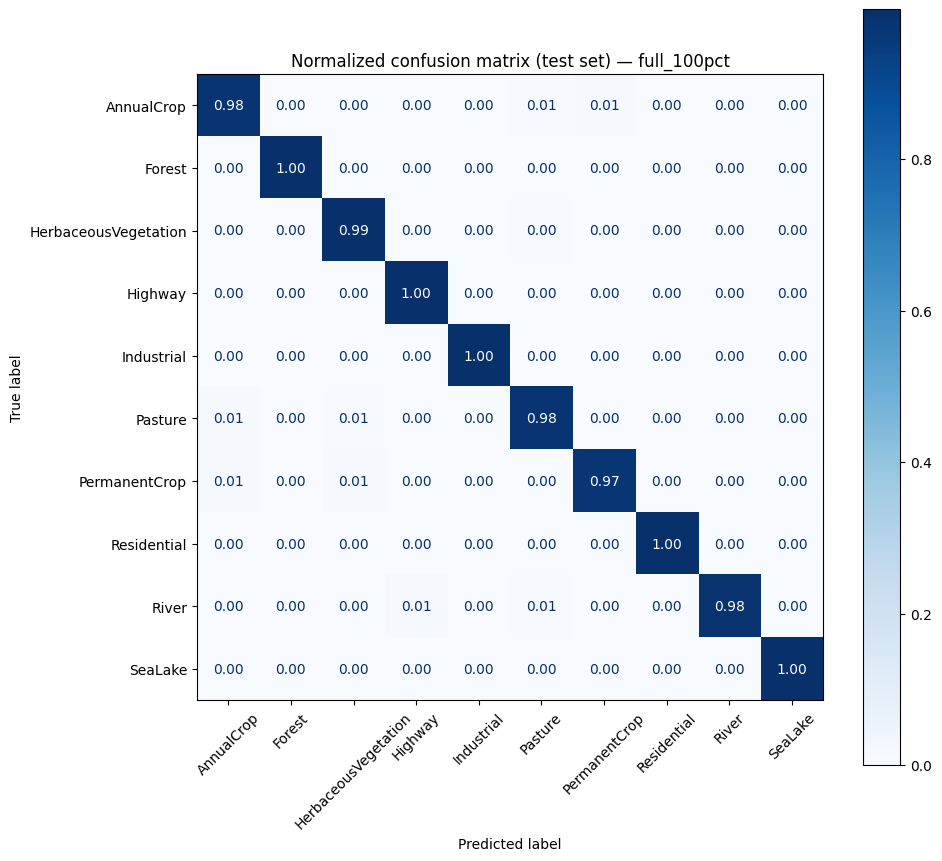

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(test_labels, test_preds, normalize="true")
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Blues", values_format=".2f", xticks_rotation=45)
ax.set_title("Normalized confusion matrix (test set) — %s" % best_name)
plt.tight_layout()
plt.show()

## g. Load a saved checkpoint and test it on unseen mini-batches

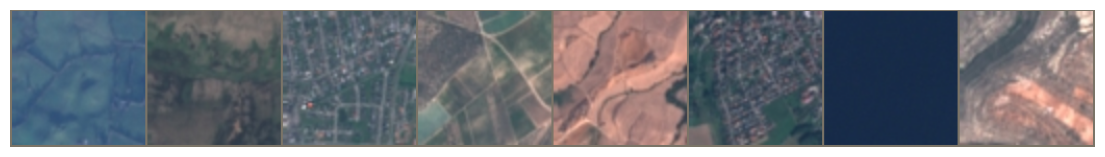

GroundTruth:  Pasture | HerbaceousVegetation | Residential | PermanentCrop | HerbaceousVegetation | Residential | SeaLake | HerbaceousVegetation
Predicted  :  Pasture (1.00) | HerbaceousVegetation (1.00) | Residential (1.00) | PermanentCrop (1.00) | HerbaceousVegetation (0.98) | Residential (1.00) | SeaLake (1.00) | HerbaceousVegetation (0.95)


In [20]:
NAME = best_name   # any run of this notebook, e.g. "frozen_5pct" or "scratch_100pct"
method = NAME.split("_")[0]
kind = "scratch" if method == "scratch" else "resnet"

trainednet, _ = make_model(method)
trainednet.load_state_dict(torch.load(os.path.join(CKPT_DIR, "NB5_%s.pth" % NAME), map_location="cpu"))
trainednet.eval()

def imshow(img, mean, std):
    img = img * torch.tensor(std).view(3, 1, 1) + torch.tensor(mean).view(3, 1, 1)
    npimg = img.clamp(0, 1).numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis("off")

demo_loader = DataLoader(test_loaders[kind].dataset, batch_size=8, shuffle=True)
images, labels = next(iter(demo_loader))
with torch.no_grad():
    outputs = trainednet(images)
    softmax = nn.Softmax(dim=1)
    probs = softmax(outputs)
    conf, predicted = torch.max(probs, 1)

plt.figure(figsize=(14, 3))
if kind == "scratch":
    imshow(torchvision.utils.make_grid(images, nrow=8), MEAN, STD)
else:
    imshow(torchvision.utils.make_grid(images, nrow=8), IMAGENET_MEAN, IMAGENET_STD)
plt.show()
print('GroundTruth: ', ' | '.join('%s' % classes[labels[j]] for j in range(8)))
print('Predicted  : ', ' | '.join('%s (%.2f)' % (classes[predicted[j]], conf[j]) for j in range(8)))